In [28]:
import os

import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from cluster_weather_years.functions import (
    build_df_centroids,
    build_df_random,
)
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    COUNTRIES,
    MODELS_FNAME,
    OUTPUT_DIR_SOLAR,
    OUTPUT_DIR_TEMP,
    OUTPUT_DIR_WIND,
    YEARS,
)

In [29]:
NUM_CLUSTERS = 5  # hardcode

# RUN_ID = "20250930_1356"  # Multi-country
RUN_ID_MAIN = "NL_20251125_1454"
LABEL_RUN_ID_MAIN = "SA, NL 5y"
LABEL_RUN_ID_MAIN_RANDOM = f"Random {NUM_CLUSTERS}y"

seed = 42
random.seed(seed)

## 1. Build dataframes

In [30]:
DF_DAILY_FNAME = os.path.join(BASE_OUTPUT, "dataframes/df_daily_multi_country_v1.csv")
df_daily_temp = pd.read_csv(DF_DAILY_FNAME, index_col=0)
df_daily_temp["Date"] = pd.to_datetime(df_daily_temp["Date"])
df_daily_temp = df_daily_temp.query(
    "Hydrological_year > 2014 and Hydrological_year < 2044"
)
df_daily_temp["model_year"] = (
    df_daily_temp["model"] + "_" + df_daily_temp["Hydrological_year"].astype(str)
)

In [31]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")
df_daily["model_year"] = (
    df_daily["model"] + "_" + df_daily["Hydrological_year"].astype(str)
)

df_daily["NL_TEMP"] = df_daily_temp["NL_TEMP"]
df_daily["NL_wind_total"] = df_daily["NL_OFF_prod"] + df_daily["NL_ON_prod"]
# ALL_MATCH_COUNTRIES = ["NL", "BE", "FR", "DE"]
ALL_MATCH_COUNTRIES = ["NL"]

vars_to_match = (
    [f"{country}_OFF_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_ON_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_SOLAR_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_Demand" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_Residual_load" for country in ALL_MATCH_COUNTRIES]
)

vars_to_standardize = vars_to_match  # df_daily.columns[3:-1].values
# df_std = standardize_df(df_daily, vars_to_standardize)

In [32]:
# add capacity factors
CAP_WIND_OFF, CAP_WIND_ON, CAP_SOLAR = (
    20 * 24,
    10 * 24,
    60 * 24,
)  # GWh/day with cf=1; very rough estimates for 2030. Multiply by 24 to deal with daily data

df_daily["NL_ON_cf"] = df_daily["NL_ON_prod"] / CAP_WIND_ON
df_daily["NL_OFF_cf"] = df_daily["NL_OFF_prod"] / CAP_WIND_OFF
df_daily["NL_SOLAR_cf"] = df_daily["NL_SOLAR_prod"] / CAP_SOLAR

In [33]:
df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_MAIN}/results_grid.csv"), index_col=0
)
df_sel_main = df_selections.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

In [ ]:
# TODO: merge nicely in src.cluster_weather_years.functions with rest
# build ds for temp, based on hourly data. Bit ugly like this.
frames_hourly = []

for model_fname, model_name in zip(MODELS_FNAME, MODELS):
    for year in YEARS:
        file_wind_off = f"P_CMI6_{model_fname}_WOF_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_20_SP245_ReGrB_PhM04_PECD4.2_fv1.csv"
        file_wind_on = f"P_CMI6_{model_fname}_WON_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_30_SP245_ReGrB_PhM04_PECD4.2_fv1.csv"
        file_solar = f"P_CMI6_{model_fname}_SPV_0000m_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_61_SP245_NA---_PhM03_PECD4.2_fv1.csv"
        file_temp = f"P_CMI6_{model_fname}_TA-_0002m_Pecd_NUT0_S{year}01010000_E{year}12312300_INS_TIM_01h_NA-_cdf_org_NA_SP245_NA---_NA---_PECD4.2_fv1.csv"

        df_wind_off = pd.read_csv(
            os.path.join(OUTPUT_DIR_WIND, file_wind_off),
            skiprows=52,
        )
        df_wind_on = pd.read_csv(
            os.path.join(OUTPUT_DIR_WIND, file_wind_on),
            skiprows=52,
        )

        df_solar = pd.read_csv(
            os.path.join(OUTPUT_DIR_SOLAR, file_solar),
            skiprows=52,
        )

        df_temp = pd.read_csv(
            os.path.join(OUTPUT_DIR_TEMP, file_temp),
            skiprows=52,
        )

        df_year = pd.DataFrame(
            {
                "Date": df_wind_off["Date"],
                **{
                    f"{country}_OFF": df_wind_off[f"{country}_OFF"]
                    for country in COUNTRIES
                },
                **{f"{country}_ON": df_wind_on[f"{country}"] for country in COUNTRIES},
                **{f"{country}_SOLAR": df_solar[f"{country}"] for country in COUNTRIES},
                **{f"{country}_TEMP": df_temp[f"{country}"] for country in COUNTRIES},
                "model": model_name,
            }
        )

        frames_hourly.append(df_year)

df_hourly = pd.concat(frames_hourly, ignore_index=True)
df_hourly["Date"] = pd.to_datetime(df_hourly["Date"])

df_hourly["Calendar_year"] = df_hourly["Date"].dt.year

df_temp = (
    df_hourly.groupby(["model", pd.Grouper(key="Date", freq="D")])["NL_TEMP"]
    .agg(Tmax="max", Tmin="min", Tmean="mean")
    .reset_index()
)
df_temp["Hydrological_year"] = (df_temp["Date"] - pd.DateOffset(months=3)).dt.year
df_temp["model_year"] = (
    df_temp["model"] + "_" + df_temp["Hydrological_year"].astype(str)
)
df_temp = df_temp.query("Hydrological_year > 2014 and Hydrological_year < 2044")

# count summer days (Tmax > 25C), hot days (Tmax > 30C), ice days (Tmax < 0C), frost days (Tmin < 0C)
df_temp["summer_days"] = (df_temp["Tmax"] > 25).astype(int)
df_temp["hot_days"] = (df_temp["Tmax"] > 30).astype(int)
df_temp["ice_days"] = (df_temp["Tmax"] < 0).astype(int)
df_temp["frost_days"] = (df_temp["Tmin"] < 0).astype(int)

# merge temp extremes into df_daily
df_daily["Tmax"] = df_temp["Tmax"]
df_daily["Tmin"] = df_temp["Tmin"]
df_daily["Tmean"] = df_temp["Tmean"]
df_daily["summer_days"] = df_temp["summer_days"]
df_daily["hot_days"] = df_temp["hot_days"]
df_daily["ice_days"] = df_temp["ice_days"]
df_daily["frost_days"] = df_temp["frost_days"]

In [35]:
# settings for random-draws
df_idx = df_daily.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [36]:
columns = vars_to_standardize.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_main)):
    datasets[f"{LABEL_RUN_ID_MAIN} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_main.iloc[i]["selected"])
    )
    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS
    )

## 2. Compute extremes

### 2.1 Mean + std plot

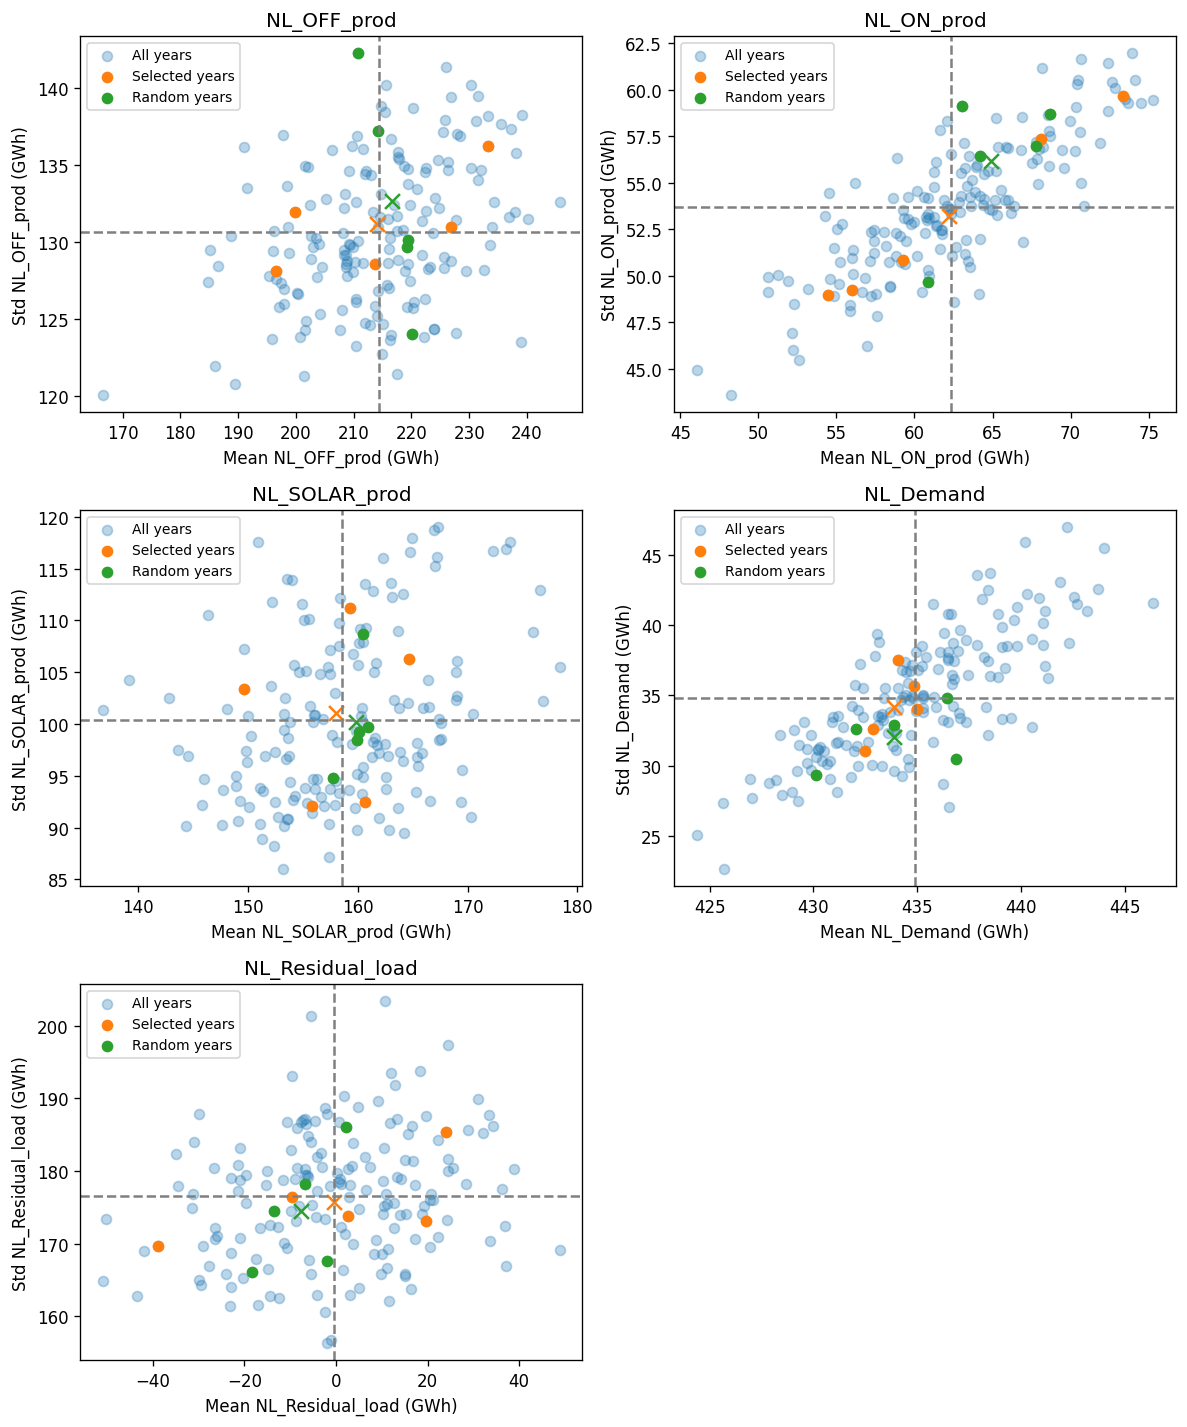

In [9]:
k = 1
fig, axes = plt.subplots(3, 2, figsize=(10, 12), dpi=120)
axes = axes.flatten()

for i, var in enumerate(vars_to_match):
    ax = axes[i]

    df_agg = df_daily.groupby("model_year")[var].agg(["mean", "std"])

    sel_agg = (
        datasets[f"{LABEL_RUN_ID_MAIN} {k}"]
        .groupby("model_year")[var]
        .agg(["mean", "std"])
    )
    random_agg = (
        datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} 1"]
        .groupby("model_year")[var]
        .agg(["mean", "std"])
    )

    ax.axhline(y=df_agg["std"].mean(), color="gray", linestyle="--")
    ax.axvline(x=df_agg["mean"].mean(), color="gray", linestyle="--")

    ax.scatter(df_agg["mean"], df_agg["std"], color="C0", label="All years", alpha=0.3)
    ax.scatter(sel_agg["mean"], sel_agg["std"], color="C1", label="Selected years")
    ax.scatter(
        sel_agg["mean"].mean(), sel_agg["std"].mean(), color="C1", marker="x", s=80
    )

    ax.scatter(random_agg["mean"], random_agg["std"], color="C2", label="Random years")
    ax.scatter(
        random_agg["mean"].mean(),
        random_agg["std"].mean(),
        color="C2",
        marker="x",
        s=80,
    )

    ax.set_xlabel(f"Mean {var} (GWh)")
    ax.set_ylabel(f"Std {var} (GWh)")
    ax.legend(fontsize="small")
    ax.set_title(var)

for j in range(len(vars_to_match), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

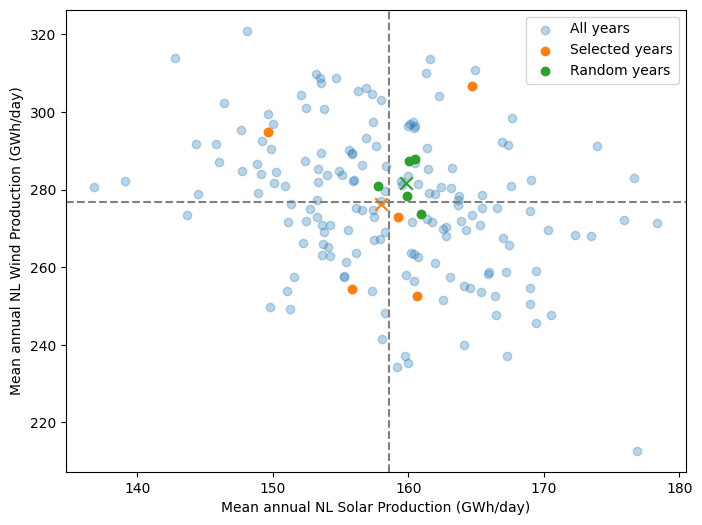

In [10]:
k = 1
mean_wind = df_daily.groupby("model_year")["NL_wind_total"].mean()
mean_solar = df_daily.groupby("model_year")["NL_SOLAR_prod"].mean()

sel_mean_wind = (
    datasets[f"{LABEL_RUN_ID_MAIN} {k}"].groupby("model_year")["NL_wind_total"].mean()
)
sel_mean_solar = (
    datasets[f"{LABEL_RUN_ID_MAIN} {k}"].groupby("model_year")["NL_SOLAR_prod"].mean()
)

random_mean_wind = (
    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} 1"]
    .groupby("model_year")["NL_wind_total"]
    .mean()
)
random_mean_solar = (
    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} 1"]
    .groupby("model_year")["NL_SOLAR_prod"]
    .mean()
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(mean_solar, mean_wind, alpha=0.3, label="All years")
ax.axhline(y=mean_wind.mean(), color="gray", linestyle="--")
ax.axvline(x=mean_solar.mean(), color="gray", linestyle="--")

ax.scatter(sel_mean_solar, sel_mean_wind, color="C1", label="Selected years")
ax.scatter(sel_mean_solar.mean(), sel_mean_wind.mean(), color="C1", marker="x", s=80)

ax.scatter(random_mean_solar, random_mean_wind, color="C2", label="Random years")
ax.scatter(
    random_mean_solar.mean(),
    random_mean_wind.mean(),
    color="C2",
    marker="x",
    s=80,
)
ax.set_xlabel("Mean annual NL Solar Production (GWh/day)")
ax.set_ylabel("Mean annual NL Wind Production (GWh/day)")
plt.legend()

### 2.2 Low production and high demand days

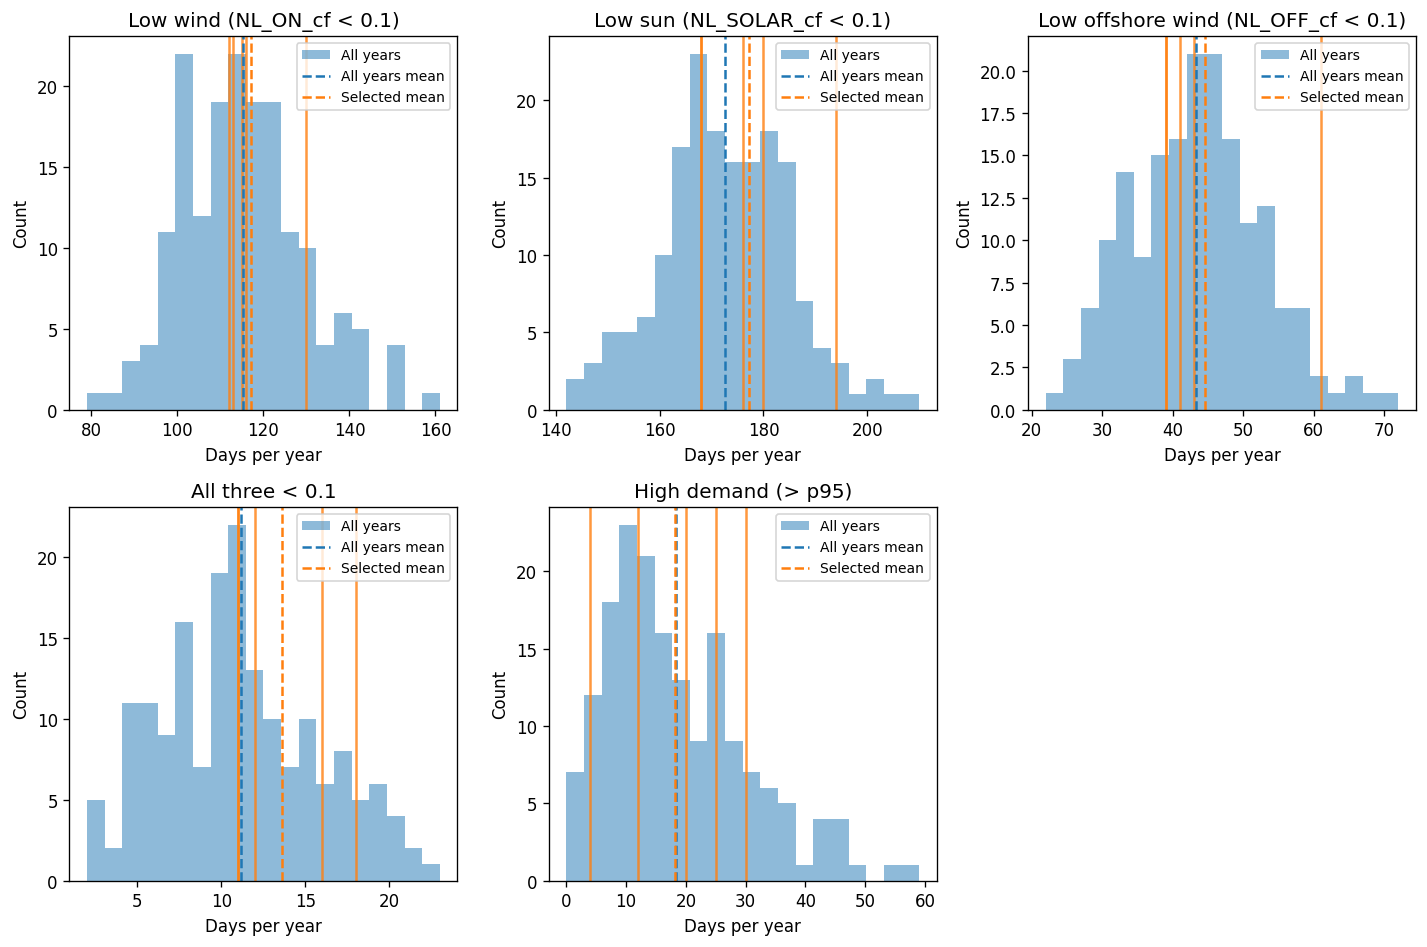

In [11]:
high_demand = df_daily["NL_Demand"].quantile(0.95)

cases = [
    ("NL_ON_cf", "Low wind (NL_ON_cf < 0.1)"),
    ("NL_SOLAR_cf", "Low sun (NL_SOLAR_cf < 0.1)"),
    ("NL_OFF_cf", "Low offshore wind (NL_OFF_cf < 0.1)"),
    ("NL_all", "All three < 0.1"),
    ("NL_Demand", "High demand (> p95)"),
]


def counts_ref(df, col):
    if col != "NL_all" and col != "NL_Demand":
        return df.groupby("model_year")[col].apply(lambda s: (s < 0.1).sum())
    if col == "NL_all":
        # combined event
        cond = (
            (df["NL_ON_cf"] < 0.1) & (df["NL_OFF_cf"] < 0.1) & (df["NL_SOLAR_cf"] < 0.1)
        )
        return df.assign(_cond=cond.astype(int)).groupby("model_year")["_cond"].sum()
    if col == "NL_Demand":
        return df.groupby("model_year")[col].apply(lambda s: (s > high_demand).sum())


def counts_sel(df_sel, col):
    if col != "NL_all" and col != "NL_Demand":
        return df_sel.groupby("model_year")[col].apply(lambda s: (s < 0.1).sum())
    if col == "NL_all":
        # combined event
        cond = (
            (df_sel["NL_ON_cf"] < 0.1)
            & (df_sel["NL_OFF_cf"] < 0.1)
            & (df_sel["NL_SOLAR_cf"] < 0.1)
        )
        return (
            df_sel.assign(_cond=cond.astype(int)).groupby("model_year")["_cond"].sum()
        )
    if col == "NL_Demand":
        return df_sel.groupby("model_year")[col].apply(
            lambda s: (s > high_demand).sum()
        )
    return df_sel.assign(_cond=cond.astype(int)).groupby("model_year")["_cond"].sum()


fig, axes = plt.subplots(2, 3, figsize=(12, 8), dpi=120)
axes = axes.flatten()

for ax, (col, title) in zip(axes, cases):
    ref_counts = counts_ref(df_daily, col)
    sel_counts = counts_sel(datasets[f"{LABEL_RUN_ID_MAIN} {k + 1}"], col)

    # histogram for reference
    n, bins, patches = ax.hist(ref_counts, bins=20, alpha=0.5, label="All years")
    ymax = n.max() * 1.05

    # vertical lines for selected years
    ax.vlines(
        sel_counts.values, ymin=0, ymax=ymax, colors="C1", alpha=0.8, linewidth=1.5
    )

    # mean lines
    ax.axvline(ref_counts.mean(), color="C0", linestyle="--", label="All years mean")
    ax.axvline(sel_counts.mean(), color="C1", linestyle="--", label="Selected mean")

    ax.set_ylim(0, ymax)
    ax.set_xlabel("Days per year")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(fontsize="small")

# turn off any extra axes (if any)
for j in range(len(cases), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

###  2.3 Temp extremes

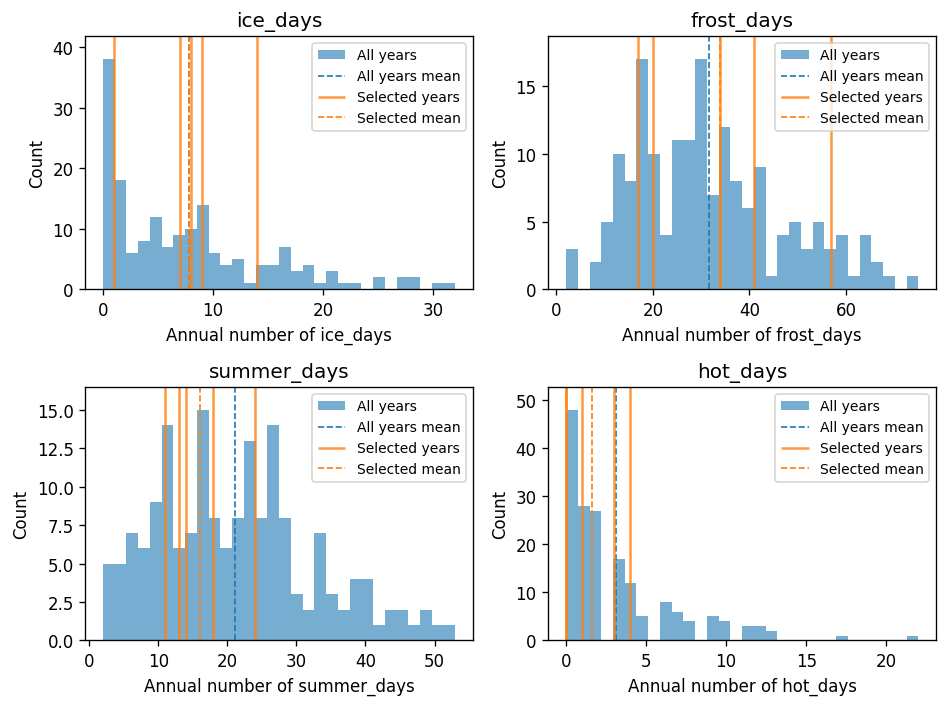

In [12]:
vars = ["ice_days", "frost_days", "summer_days", "hot_days"]
k = 1

fig, axes = plt.subplots(2, 2, figsize=(8, 6), dpi=120)
axes = axes.flatten()

for ax, var in zip(axes, vars):
    ref_series = df_temp.groupby("model_year")[var].sum()
    sel_series = (
        datasets[f"{LABEL_RUN_ID_MAIN} {k + 1}"].groupby("model_year")[var].sum()
    )

    # histogram for reference and compute ymax for line scaling
    n, bins, patches = ax.hist(ref_series, bins=30, alpha=0.6, label="All years")
    ymax = n.max() * 1.10

    # reference mean
    ax.axvline(
        ref_series.mean(),
        color="C0",
        linestyle="dashed",
        linewidth=1,
        label="All years mean",
    )

    # selected years as vertical lines and selected mean
    ax.vlines(
        sel_series.values,
        ymin=0,
        ymax=ymax,
        colors="C1",
        alpha=0.8,
        linewidth=1.5,
        label="Selected years",
    )
    ax.axvline(
        sel_series.mean(),
        color="C1",
        linestyle="dashed",
        linewidth=1,
        label="Selected mean",
    )

    ax.set_title(f"{var}")
    ax.set_xlabel(f"Annual number of {var}")
    ax.set_ylabel("Count")
    ax.set_ylim(0, ymax)
    ax.legend(fontsize="small")

plt.tight_layout()
plt.show()

### 2.4 Annual climatology

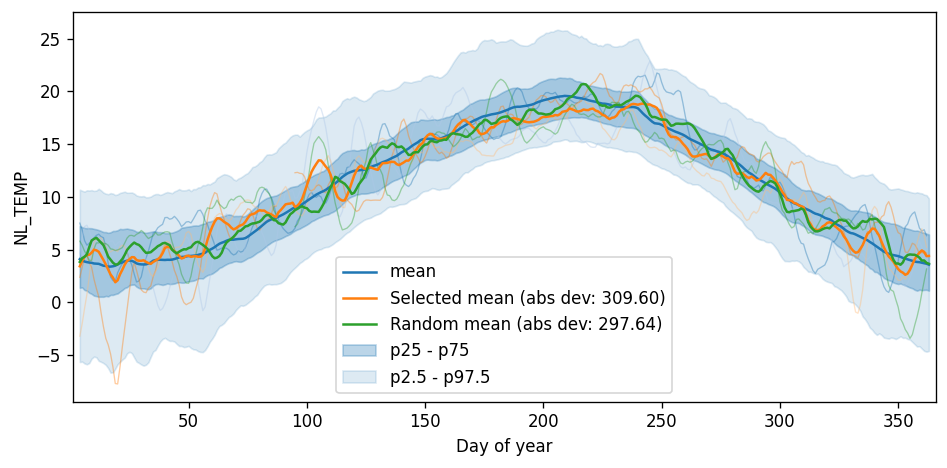

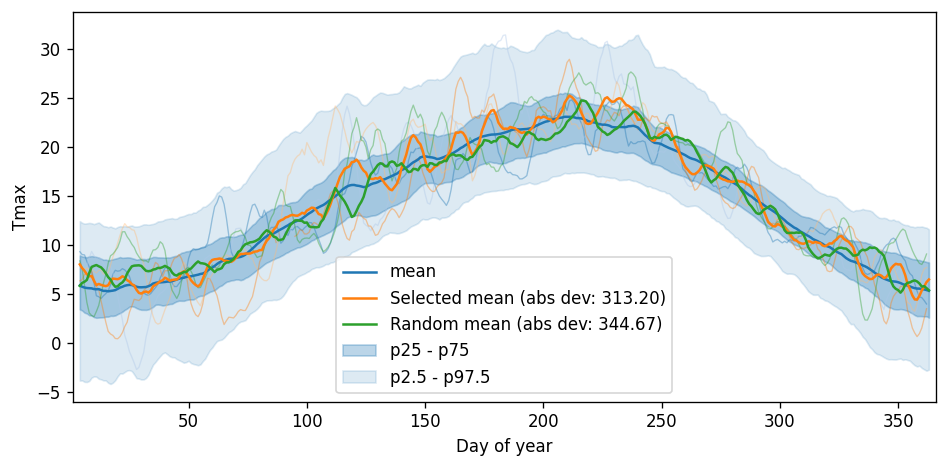

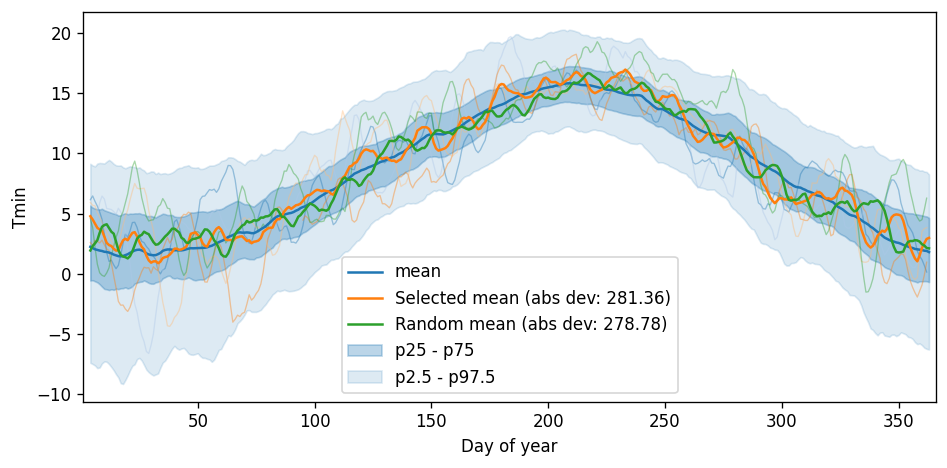

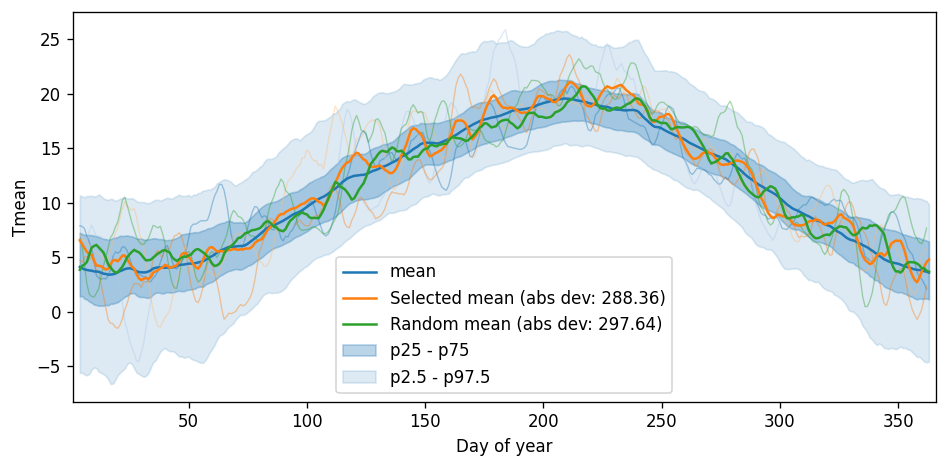

In [41]:
i = 0
vars = ["NL_TEMP", "Tmax", "Tmin", "Tmean"]

for var in vars:
    df_plot = df_daily.copy()
    df_plot = df_plot[
        ~((df_plot["Date"].dt.month == 2) & (df_plot["Date"].dt.day == 29))
    ]

    df_sel = datasets[f"{LABEL_RUN_ID_MAIN} {i + 1}"]
    df_sel["doy"] = df_sel["Date"].dt.dayofyear

    df_random = datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} 1"]
    df_random["doy"] = df_random["Date"].dt.dayofyear

    clim = (
        df_plot.groupby(df_plot["Date"].dt.dayofyear)[var]
        .agg(
            mean="mean",
            p2_5=lambda x: np.percentile(x, 2.5),
            p25=lambda x: np.percentile(x, 25),
            p75=lambda x: np.percentile(x, 75),
            p97_5=lambda x: np.percentile(x, 97.5),
        )
        .rolling(window=7, center=True)
        .mean()
    )

    clim_sel = (
        df_sel.groupby(df_sel["doy"])[var]
        .agg(
            mean="mean",
            p2_5=lambda x: np.percentile(x, 2.5),
            p25=lambda x: np.percentile(x, 25),
            p75=lambda x: np.percentile(x, 75),
            p97_5=lambda x: np.percentile(x, 97.5),
        )
        .rolling(window=7, center=True)
        .mean()
    )

    clim_random = (
        df_random.groupby(df_random["doy"])[var]
        .agg(
            mean="mean",
            p2_5=lambda x: np.percentile(x, 2.5),
            p25=lambda x: np.percentile(x, 25),
            p75=lambda x: np.percentile(x, 75),
            p97_5=lambda x: np.percentile(x, 97.5),
        )
        .rolling(window=7, center=True)
        .mean()
    )
    absdev_random = abs(clim_random["mean"] - clim["mean"]).sum()
    absdev_sel = abs(clim_sel["mean"] - clim["mean"]).sum()

    fig, ax = plt.subplots(figsize=(8, 4), dpi=120)

    # colormap for individual years
    cmap = plt.get_cmap("tab20")
    for i, (model_year, g) in enumerate(df_sel.groupby("model_year")):
        s = (
            g.groupby("doy")[var]
            .mean()
            .reindex(range(1, 366))
            .rolling(window=7, center=True)
            .mean()
        )  # ensure full doy 1..365
        ax.plot(s.index, s.values, color=cmap(i % cmap.N), linewidth=0.8, alpha=0.4)

    x = clim.index
    ax.plot(x, clim["mean"], color="C0", label="mean")
    ax.plot(
        x,
        clim_sel["mean"],
        color="C1",
        label=f"Selected mean (abs dev: {absdev_sel:.2f})",
    )
    ax.plot(
        x,
        clim_random["mean"],
        color="C2",
        label=f"Random mean (abs dev: {absdev_random:.2f})",
    )
    ax.fill_between(
        x, clim["p25"], clim["p75"], color="C0", alpha=0.3, label="p25 - p75"
    )
    ax.fill_between(
        x, clim["p2_5"], clim["p97_5"], color="C0", alpha=0.15, label="p2.5 - p97.5"
    )

    ax.set_xlabel("Day of year")
    ax.set_ylabel(var)
    ax.set_xlim(1, 366)
    ax.legend()
    plt.tight_layout()
